
# 22 订单容量与可实现收益

> **本章要解决的问题**：回测说“买 20 手”，盘口只有 5 手深度，实际能成交多少？未成交的部分，是少赚还是改变了策略？容量曲线怎样画？

## 本章导读

第14章讲回放对账，第22章讲**容量**：

- 逐分钟/逐档成交量约束；
- 理想、实际、错过、冲击；
- 规模越大，净利越薄；
- 容量曲线与最优规模。

### 学习目标

- 会按逐分钟成交量设成交上限。
- 能分解理想/实际/错过/冲击。
- 会做逐档填充，并算平均成交价。
- 能画容量曲线，判断最优规模。

### 先修

第01章的成本；第14章的回放；会 pandas。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="22 订单容量与可实现收益" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>22 订单容量与可实现收益｜知识图</title>
<desc>本章主线：逐分钟设成交上限，再逐档填充；规模越大，冲击越贵，容量曲线见顶。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a31" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao31" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag31" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">22</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">订单容量与可实现收益</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：逐分钟设成交上限，再逐档填充；规模越大，冲击越贵，容量曲线见顶。</text>
<rect x="41" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="121" y="141.3" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">目标手数与盘口深度</text>
<text x="121" y="161.4" font-size="10.5" fill="#6E7B8B" text-anchor="middle">分钟成交量、费用</text>
<rect x="51" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="68" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">输入</text>
<rect x="227" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="307" y="132.1" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">逐分钟上限 + 逐档填</text>
<text x="307" y="150.6" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">充</text>
<text x="307" y="170.6" font-size="10.5" fill="#6E7B8B" text-anchor="middle">不能总成交量乘比例</text>
<rect x="237" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="254" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">处理</text>
<rect x="413" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="493" y="141.3" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">实际 / 错过 / 冲击</text>
<text x="493" y="161.4" font-size="10.5" fill="#6E7B8B" text-anchor="middle">平均成交价与机会成本</text>
<rect x="423" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="440" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">输出</text>
<rect x="599" y="88" width="160" height="122" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="679" y="141.3" font-size="13.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">容量曲线与最优规模</text>
<text x="679" y="161.4" font-size="10.5" fill="#6E7B8B" text-anchor="middle">规模↑ 净利↓</text>
<rect x="609" y="97" width="34" height="17" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.1" rx="7"/>
<text x="626" y="109.5" font-size="9.5" fill="#6E7B8B" text-anchor="middle">检查</text>
<path d="M 201 149 L 227 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a31)"/>
<path d="M 387 149 L 413 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a31)"/>
<path d="M 573 149 L 599 149" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a31)"/>
<rect x="41" y="232" width="718" height="152" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<rect x="58" y="246" width="4" height="11" fill="#E07B39" rx="1"/>
<text x="70" y="256" font-size="11.5" fill="#1B3A5C" font-weight="bold">订单容量曲线</text>
<path d="M 95 360 L 700 360" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag31)"/>
<path d="M 95 360 L 95 274" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag31)"/>
<text x="702" y="374" font-size="8.6" fill="#6E7B8B" text-anchor="end">规模</text>
<text x="98" y="272" font-size="8.6" fill="#6E7B8B">净利</text>
<path d="M 95 352 L 106 349 L 117 346.1 L 128 343.2 L 139 340.5 L 150 337.8 L 161 335.2 L 172 332.7 L 183 330.3 L 194 328 L 205 325.7 L 216 323.6 L 227 321.5 L 238 319.5 L 249 317.6 L 260 315.8 L 271 314.1 L 282 312.5 L 293 310.9 L 304 309.5 L 315 308.1 L 326 306.8 L 337 305.6 L 348 304.5 L 359 303.4 L 370 302.5 L 381 301.6 L 392 300.9 L 403 300.2 L 414 299.6 L 425 299.1 L 436 298.7 L 447 298.3 L 458 298.1 L 469 297.9 L 480 297.8 L 491 297.8 L 502 297.9 L 513 298.1 L 524 298.4 L 535 298.7 L 546 299.2 L 557 299.7 L 568 300.3 L 579 301 L 590 301.8 L 601 302.7 L 612 303.6 L 623 304.7 L 634 305.8 L 645 307" fill="none" stroke="#1B3A5C" stroke-width="1.9" stroke-linecap="round" stroke-linejoin="round"/>
<circle cx="513" cy="298.1" r="5.5" fill="#E07B39" stroke="#E07B39" stroke-width="1.4"/>
<line x1="513" y1="303.1" x2="513" y2="358" stroke="#E07B39" stroke-width="1.2" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="521" y="290.1" font-size="8.8" fill="#E07B39" font-weight="bold">最优规模</text>
<rect x="513" y="300" width="150" height="58" fill="#E6EFF7" rx="4" opacity="0.5"/>
<text x="521" y="345" font-size="8.6" fill="#6E7B8B">容量上限区</text>
<text x="120" y="290" font-size="9" fill="#1B3A5C">逐分钟 10% 上限 + 逐档填充</text>
</svg>

> **图**：本章主线：逐分钟设成交上限，再逐档填充；规模越大，冲击越贵，容量曲线见顶。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：执行、策略容量、交易员。
- **输入**：目标手数、分钟成交量、盘口深度、费用。
- **输出**：成交/未成交、冲击价、容量曲线。
- **在流程的哪一步**：规模放大与执行约束。
- **失败模式**：总成交量乘比例、忽略未成交机会成本、只算一个规模。
- **最小工作流**：逐分钟上限 → 逐档填充 → 实际/错过 → 成本 → 容量曲线。

---
## 1. 成交上限

### 1.1 规则

每一分钟最多成交“该分钟成交量的 10%”（教学假设）。先逐分钟限制，再汇总；不能先用总成交量乘 10%。

**公式拆解**
- **符号**：$V_t$ 第 $t$ 分钟市场成交量（手），$\rho$ 参与率（10%），$q^{rem}_t$ 剩余目标手数。
- **结构**：$c_t=\min(q^{rem}_t,\lfloor\rho V_t\rfloor)$ 逐分钟截断再求和，不能先汇总再乘。
- **代入**：12、25、46 → $1+2+4=7$ 手；先汇总得 8 手，多算 1 手。
- **边界**：$V_t=0$ 或 $\rho=0$ 不成交；向下取整会系统性少算。
- **用途**：回测执行约束与容量；10% 是假设，不是成交概率，也不含冲击。

### 1.2 代码



In [2]:

import numpy as np

vol = np.array([12, 25, 46])
cap = np.floor(0.1 * vol).astype(int)
print("逐分钟上限", cap, "合计", cap.sum())
print("先汇总的错误上限", int(0.1 * vol.sum()))


逐分钟上限 [1 2 4] 合计 7
先汇总的错误上限 8



**读数**：逐分钟上限 (1,2,4) 合计 7；先汇总得 8，多算 1 手。

**常见错误**：

1. 用总成交量乘比例。
2. 忽略盘口深度。
3. 假设市价单无限成交。

---

## 2. 理想、实际、错过

### 2.1 分解

- 理想：目标全部成交；
- 实际：受上限/价格约束成交；
- 错过：未成交部分的机会成本；
- 冲击：实际成交价差。

**公式拆解**
- **符号**：$Q,q$ 目标/成交，$P_e$ 出场、$P_r$ 基准、$\bar P$ 均价、$M$ 乘数。
- **结构**：理想 $=Q(P_e-P_r)M$、实际 $=q(P_e-\bar P)M$、错过 $=(Q-q)(P_e-P_r)M$；恒等式 理想=实际+错过+冲击。
- **代入**：$Q=5$、$q=3$、$P_e=103$、$P_r=100$、$\bar P=101$、$M=10$ → $150=60+60+30$。
- **边界**：$q=0$ 时实际 0、错过=理想；机会成本符号随行情反转。
- **用途**：拆容量（没成交 vs 买贵）；不是现金流或冲击模型。

### 2.2 代码



In [3]:

for close in [103, 98]:
    ideal = 5 * (close - 100) * 10
    real = 3 * (close - 101) * 10
    missed = 2 * (close - 100) * 10
    print("到期价", close, "理想/实际/错过", ideal, real, missed)


到期价 103 理想/实际/错过 150 60 60
到期价 98 理想/实际/错过 -100 -90 -40



**读数**：只成交 3 手、价格差 1 点，实际远低于理想；未成交的 2 手是“错过”，不是“没成本”。

**常见错误**：

1. 只算成交部分。
2. 忽略未成交的机会成本。
3. 不区分“没做”和“做了一半”。

---

## 3. 逐笔填充与容量曲线

### 3.1 填充

按分钟/价位逐档吃量；目标越大，越往后吃，价格越差。

### 3.2 容量曲线

横轴目标手数，纵轴净利；通常先升后降，存在“最优规模”。

### 3.3 代码



In [4]:

def fill(target, prices=(100.0, 101.0, 103.0), volumes=(30, 50, 60)):
    remaining, fills = target, []
    for price, volume in zip(prices, volumes):
        qty = min(remaining, int(0.1 * volume))
        if qty:
            fills.append((qty, price + 0.5))
            remaining -= qty
    return fills, remaining

for size in [1, 8, 20]:
    fills, left = fill(size)
    print("目标", size, "成交", fills, "剩余", left)


目标 1 成交 [(1, 100.5)] 剩余 0
目标 8 成交 [(3, 100.5), (5, 101.5)] 剩余 0
目标 20 成交 [(3, 100.5), (5, 101.5), (6, 103.5)] 剩余 6



**读数**：目标 20 手只能成交一部分，剩余未成交；规模越大，平均成交价越差。

**常见错误**：

1. 用一档价格乘全部数量。
2. 不做逐档/逐分钟。
3. 不画容量曲线。

---

## 4. 案例：容量曲线

假设出场价 103、每手费用 4 元，目标 5/20/50 手，用上面的逐档填充：

**公式拆解**
- **符号**：$q_k,P_k$ 第 $k$ 档成交手数/价格，$P_{exit}$ 出场价，$M$ 乘数，$fee$ 每手费用。
- **结构**：$\bar P_{fill}=\sum q_kP_k/\sum q_k$；净利 $=(P_{exit}-\bar P_{fill})qM-q\cdot fee$。
- **代入**：$3@100.5$、$5@101.5$ → 均价 101.125、毛利 150、费用 32、净利 118 元。
- **边界**：$q=0$ 均价无定义；均价高于出场价则毛利为负。
- **用途**：画容量曲线、找最优规模；不是可实现收益，VWAP 也不是公平价。



In [5]:

for size in [5, 20, 50]:
    fills, left = fill(size)
    done = size - left
    net = sum(q * (103 - p) for q, p in fills) * 10 - done * 4
    print("目标", size, "成交", done, "剩余", left, "净利", round(net, 1))


目标 5 成交 5 剩余 0 净利 85.0
目标 20 成交 14 剩余 6 净利 64.0
目标 50 成交 14 剩余 36 净利 64.0



**读数**：目标越大，未成交越多、平均成交价越差，净利先升后降或直接下降；这就是容量约束。

**常见错误**：

1. 认为“目标越大，收益越大”。
2. 不报告未成交比例。
3. 不做规模敏感性。

---

## 5. 画容量曲线

把目标手数从 1 扫到 30，记录净利，画出来：



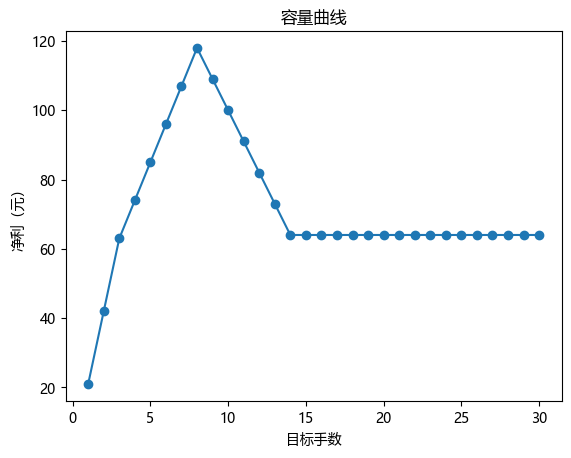

最优规模 8 最高净利 118.0


In [6]:

import matplotlib.pyplot as plt

sizes = list(range(1, 31))
nets = []
for size in sizes:
    fills, left = fill(size)
    done = size - left
    nets.append(sum(q * (103 - p) for q, p in fills) * 10 - done * 4)

plt.plot(sizes, nets, "o-")
plt.xlabel("目标手数")
plt.ylabel("净利（元）")
plt.title("容量曲线")
plt.show()
print("最优规模", sizes[int(max(range(len(nets)), key=nets.__getitem__))], "最高净利", round(max(nets), 1))



**读数**：净利随规模先升后降；最优点不是“越大越好”。真实容量还要加冲击成本/深度限制。

**常见错误**：

1. 只算一个规模。
2. 不画曲线。
3. 不报告假设。

---

## 本章小结

### 一张表

| 概念 | 做法 | 用途 |
|---|---|---|
| 逐分钟上限 | min(目标, 比例×量) | 成交约束 |
| 理想/实际/错过 | 分解 | 归因 |
| 逐档填充 | 吃量 | 价格冲击 |
| 容量曲线 | 规模 vs 净利 | 最优规模 |

### 六句话

1. 先逐分钟限制，再汇总。
2. 未成交有机会成本。
3. 规模越大，价格越差。
4. 容量曲线通常先升后降。
5. 回测要报告假设。
6. 容量是策略的一部分。

---

## 本章习题

**1.** 三分钟成交量 12/25/46，10% 上限，逐分钟合计多少？

**2.** 先汇总再乘 10% 会多算多少？

**3.** 目标 20 手、上限合计 7 手，剩余多少？

**4.** 为什么未成交也有成本？

**5.** 容量曲线为什么先升后降？

<details><summary>参考答案</summary>

**1.** 1+2+4=7。

**2.** 8−7=1 手。

**3.** 13 手。

**4.** 错过机会/改变策略暴露。

**5.** 规模带来收益，但冲击/未成交/费用上升，净利下降。

</details>

---

## 参考资料

- 第14章；市场冲击/容量实践。
